# Air Quality Analysis of Indian Cities (2015-2020)
Analysing AQI trends across cities and seasons using Python and SQL.

In [3]:
import glob
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
path = glob.glob("/kaggle/input/**/city_day.csv", recursive=True)[0]
df = pd.read_csv(path)

In [5]:
df.head()    #to look at the data

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [6]:
df.shape     #checks the size

(29531, 16)

In [7]:
df.isnull().sum()       #to see the empty cell

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [8]:
df["City"].nunique()       # no. of cities

26

In [9]:
df["City"].unique()      # city names

array(['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru',
       'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore',
       'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad',
       'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai',
       'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram',
       'Visakhapatnam'], dtype=object)

In [10]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes

City                  object
Date          datetime64[ns]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket            object
dtype: object

In [11]:
df = df.dropna(subset=["AQI"])  # remove rows with no AQI
df.shape

(24850, 16)

In [12]:
df = df[df["AQI"] <= 500]   # remove impossible values
df.shape

(24307, 16)

In [13]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df[["Date", "Year", "Month"]].head()

,Date,Year,Month
28,2015-01-29,2015,1
29,2015-01-30,2015,1
34,2015-02-04,2015,2
35,2015-02-05,2015,2
36,2015-02-06,2015,2


In [14]:
def get_season(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Summer"
    elif m in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)
df[["Date", "City", "AQI", "Season"]].head()

,Date,City,AQI,Season
28,2015-01-29,Ahmedabad,209.0,Winter
29,2015-01-30,Ahmedabad,328.0,Winter
34,2015-02-04,Ahmedabad,294.0,Winter
35,2015-02-05,Ahmedabad,149.0,Winter
36,2015-02-06,Ahmedabad,190.0,Winter


In [15]:
df["Season"].value_counts()  #check the seasons

Season
Monsoon         7619
Summer          6965
Winter          6063
Post-Monsoon    3660
Name: count, dtype: int64

In [16]:
#set up sql
conn = sqlite3.connect(":memory:")
df.to_sql("air", conn, index=False, if_exists="replace")

24307

In [17]:
#which cities have the worst air?
query = """
SELECT City, ROUND(AVG(AQI), 1) AS avg_aqi, COUNT(*) AS days
FROM air
GROUP BY City
ORDER BY avg_aqi DESC
LIMIT 5
"""
pd.read_sql(query, conn)

,City,avg_aqi,days
0,Ahmedabad,291.7,922
1,Delhi,252.1,1951
2,Patna,235.6,1434
3,Gurugram,219.4,1431
4,Lucknow,215.2,1878


In [18]:
#shows worst season
query = """
SELECT Season, ROUND(AVG(AQI), 1) AS avg_aqi
FROM air
GROUP BY Season
ORDER BY avg_aqi DESC
"""
pd.read_sql(query, conn)

,Season,avg_aqi
0,Winter,203.9
1,Post-Monsoon,190.0
2,Summer,138.3
3,Monsoon,109.3


In [19]:
#How did AQI change over the years?
query = """
SELECT Year, ROUND(AVG(AQI), 1) AS avg_aqi, COUNT(DISTINCT City) AS cities
FROM air
GROUP BY Year
ORDER BY Year
"""
pd.read_sql(query, conn)

,Year,avg_aqi,cities
0,2015,199.4,7
1,2016,187.8,9
2,2017,171.0,15
3,2018,159.2,18
4,2019,143.2,23
5,2020,110.9,26


In [20]:
query = """
SELECT Year, ROUND(AVG(AQI), 1) AS avg_aqi, COUNT(DISTINCT City) AS cities
FROM air
WHERE Month <= 6
  AND City IN (SELECT DISTINCT City FROM air WHERE Year = 2015)
GROUP BY Year
ORDER BY Year
"""
pd.read_sql(query, conn)

,Year,avg_aqi,cities
0,2015,203.5,6
1,2016,193.4,7
2,2017,184.9,6
3,2018,188.3,7
4,2019,184.0,7
5,2020,131.2,7


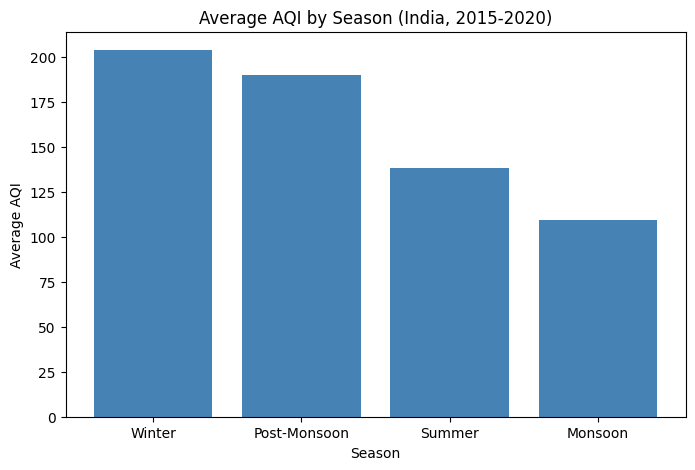

In [21]:
#chart of aqi by season 
query = """
SELECT Season, ROUND(AVG(AQI), 1) AS avg_aqi
FROM air
GROUP BY Season
ORDER BY avg_aqi DESC
"""
season_df = pd.read_sql(query, conn)

plt.figure(figsize=(8, 5))
plt.bar(season_df["Season"], season_df["avg_aqi"], color="steelblue")
plt.title("Average AQI by Season (India, 2015-2020)")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.show()

**Winter has the highest average AQI and monsoon the lowest.**

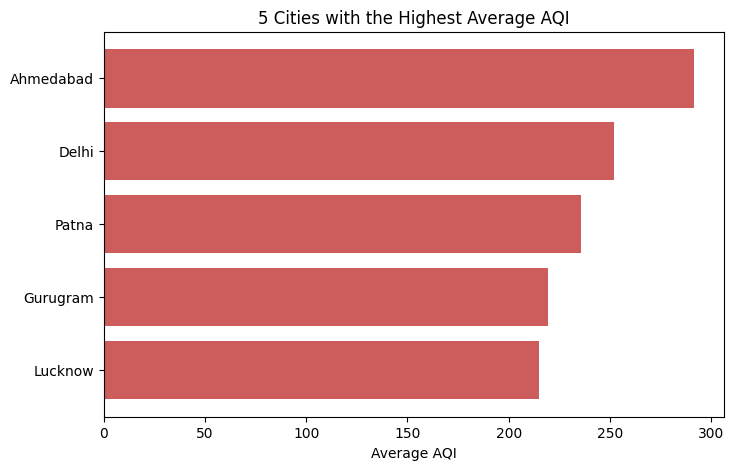

In [22]:
#chart of the worst 5 cities
query = """
SELECT City, ROUND(AVG(AQI), 1) AS avg_aqi
FROM air
GROUP BY City
ORDER BY avg_aqi DESC
LIMIT 5
"""
city_df = pd.read_sql(query, conn)

plt.figure(figsize=(8, 5))
plt.barh(city_df["City"], city_df["avg_aqi"], color="indianred")
plt.gca().invert_yaxis()
plt.title("5 Cities with the Highest Average AQI")
plt.xlabel("Average AQI")
plt.show()

**Ahmedabad ranks highest, but about 400 of its readings above 500 were removed as invalid, and it has less data than other cities.**

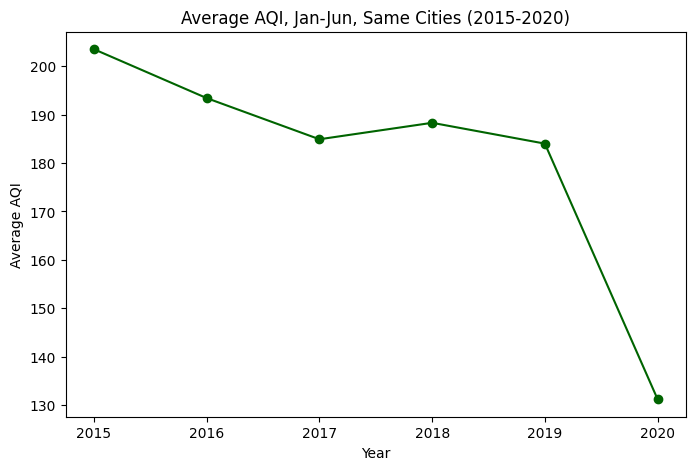

In [23]:
#chart of the fair yearly trend
query = """
SELECT Year, ROUND(AVG(AQI), 1) AS avg_aqi
FROM air
WHERE Month <= 6
  AND City IN (SELECT DISTINCT City FROM air WHERE Year = 2015)
GROUP BY Year
ORDER BY Year
"""
trend_df = pd.read_sql(query, conn)

plt.figure(figsize=(8, 5))
plt.plot(trend_df["Year"], trend_df["avg_aqi"], marker="o", color="darkgreen")
plt.title("Average AQI, Jan-Jun, Same Cities (2015-2020)")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.show()

**On the same 7 cities and Jan-Jun months, AQI was roughly flat from 2015 to 2019 and dropped sharply in 2020.**

## Limitations :

1. Cities cover different time periods.
2. AQI above 500 was removed as outside the official scale.
3. 2020 has no data after mid-year, and the drop coincides with the COVID
   lockdown, but the data can’t prove the cause.